# ML_for_Business_CA1

In [1]:
import warnings 
warnings.filterwarnings('ignore')

In [16]:
# !pip install matplotlib scikit-learn scikit-fuzzy pandas
# !pip install pyclustering

In [17]:
# Load the following libraries for the task
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
# Load the dataset
df=pd.read_csv("stock_data.csv")

In [19]:
# Display top 5 records
df.head()

,Date,Ticker,Open,High,Low,Close,Volume
0,2016-10-24,AAPL,26.779087,26.925446,26.756219,26.904865,94154800
1,2016-10-25,AAPL,26.973472,27.067234,26.827113,27.042078,192516000
2,2016-10-26,AAPL,26.141054,26.458927,25.912368,26.433771,264536800
3,2016-10-27,AAPL,26.388037,26.495519,26.093032,26.179934,138248000
4,2016-10-28,AAPL,26.040437,26.346875,25.944388,26.006134,151446800


In [20]:
# Characterization of the data set
print("~DATASET DESCRIPTION~".center(50))
print(f"Data size:                                     {df.shape}")
print(f"Number of observations:                             {df.shape[0]}")
print(f"Number of variable:                                     {df.shape[1]}")
print(f"Number of categorical variable:                         {len(df.select_dtypes(include='object').columns)}")
print(f"Number of numerical variable:                           {len(df.select_dtypes(include=['int64', 'float64']).columns)}")

              ~DATASET DESCRIPTION~               
Data size:                                     (20096, 7)
Number of observations:                             20096
Number of variable:                                     7
Number of categorical variable:                         2
Number of numerical variable:                           5


In [21]:
print("~Data type of each column~")
print(df.dtypes)

~Data type of each column~
Date       object
Ticker     object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


In [22]:
# Check for missing values
print("~MISSING VALUES~")
missing_values=df.isnull().sum()
missing_values_df = pd.DataFrame({
    'Missing Values': missing_values
})
missing_values_yes = missing_values_df[missing_values_df['Missing Values'] > 0]
print(f"\n Columns with missing values: {missing_values_yes.shape[0]}")
print(f"Total columns in dataset: {df.shape[1]}")
print(f"Total rows: {df.shape[0]}")

~MISSING VALUES~

 Columns with missing values: 0
Total columns in dataset: 7
Total rows: 20096


In [23]:
#Display the basic statistics
print("~BASIC STATISTICAL MEASURES~".center(70))
print(df.groupby("Ticker")[["Open","High","Low","Close","Volume"]].describe().T)

                     ~BASIC STATISTICAL MEASURES~                     
Ticker                AAPL           JNJ           JPM            KO  \
Open   count  2.512000e+03  2.512000e+03  2.512000e+03  2.512000e+03   
       mean   1.356005e+02  1.405463e+02  1.465965e+02  5.031639e+01   
       std    8.275844e+01  3.824186e+01  7.892395e+01  1.414939e+01   
       min    2.449615e+01  8.480448e+01  5.269035e+01  2.980800e+01   
       25%    4.896548e+01  1.113369e+02  8.796744e+01  3.781840e+01   
       50%    1.395674e+02  1.403251e+02  1.196305e+02  4.852410e+01   
       75%    1.901952e+02  1.512227e+02  1.837386e+02  5.778825e+01   
       max    3.469500e+02  2.773200e+02  3.646806e+02  9.368000e+01   
High   count  2.512000e+03  2.512000e+03  2.512000e+03  2.512000e+03   
       mean   1.370978e+02  1.416281e+02  1.480098e+02  5.066894e+01   
       std    8.366544e+01  3.864285e+01  7.966054e+01  1.426210e+01   
       min    2.475130e+01  8.531082e+01  5.283676e+01  2.987457e

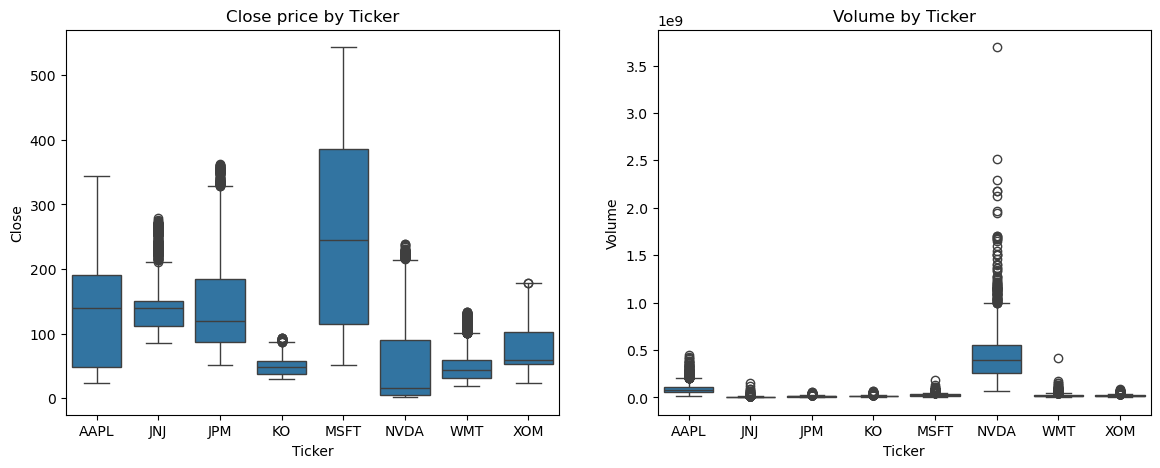

In [24]:
# Check the outliers
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.boxplot(data=df, x="Ticker", y="Close", ax=axes[0])
axes[0].set_title("Close price by Ticker")
sns.boxplot(data=df, x="Ticker", y="Volume", ax=axes[1])
axes[1].set_title("Volume by Ticker")
plt.show()

In [25]:
# Convert Date to datetime
if "Date" not in df.columns:
    df = df.reset_index()
df["Date"] = pd.to_datetime(df["Date"])

# Check for duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate (Date, Ticker):", df.duplicated(subset=["Date","Ticker"]).sum())
df = df.drop_duplicates(subset=["Date","Ticker"])

# Sort by Ticker and Date
df = df.sort_values(["Ticker","Date"]).reset_index(drop=True)
print(df.dtypes)
print(df["Date"].min(), "->", df["Date"].max())

Duplicate rows: 0
Duplicate (Date, Ticker): 0
Date      datetime64[ns]
Ticker            object
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
dtype: object
2016-10-24 00:00:00 -> 2026-10-21 00:00:00


In [26]:
gp = df.groupby("Ticker")

df["Return"]       = gp["Close"].pct_change()                      
df["Log_Return"]   = np.log(df["Close"] / gp["Close"].shift(1))
df["Volatility_20"] = gp["Return"].transform(lambda x: x.rolling(20).std())
df["MA_50"]        = gp["Close"].transform(lambda x: x.rolling(50).mean())
df["Price_Range"]  = (df["High"] - df["Low"]) / df["Close"]      
df["Log_Volume"]   = np.log(df["Volume"])

# Remove NaN values created by pct_change and rolling windows
before = len(df)
df_feat = df.dropna().reset_index(drop=True)
print(f"~Dropped {before - len(df_feat)} rows with NaN (first rows of rolling windows)~")
print(df_feat.head())

~Dropped 392 rows with NaN (first rows of rolling windows)~
        Date Ticker       Open       High        Low      Close     Volume  \
0 2017-01-04   AAPL  26.629255  26.780964  26.606270  26.668331   84472400   
1 2017-01-05   AAPL  26.645344  26.861412  26.620059  26.803947   88774400   
2 2017-01-06   AAPL  26.843023  27.160231  26.771767  27.102766  127007600   
3 2017-01-09   AAPL  27.111961  27.452154  27.109663  27.351015  134247600   
4 2017-01-10   AAPL  27.300446  27.440661  27.192413  27.378599   97848400   

     Return  Log_Return  Volatility_20      MA_50  Price_Range  Log_Volume  
0 -0.001119   -0.001120       0.006830  25.905239     0.006551   18.251935  
1  0.005085    0.005072       0.006762  25.903221     0.009004   18.301609  
2  0.011148    0.011087       0.006839  25.904434     0.014333   18.659757  
3  0.009160    0.009118       0.006806  25.922779     0.012522   18.715196  
4  0.001009    0.001008       0.006047  25.946753     0.009067   18.398930  


In [27]:
def max_drawdown(close):
    # Largest peak-to-trough decline over the period
    peak = close.cummax()
    return ((close - peak) / peak).min()

summary = df_feat.groupby("Ticker").agg(
    # annualised
    Annual_Return=("Return", lambda x: x.mean() * 252),                       
    Annual_Volatility=("Return", lambda x: x.std() * np.sqrt(252)), 
    # average
    Avg_Price_Range=("Price_Range", "mean"),
    Avg_Log_Volume=("Log_Volume", "mean"),
)
summary["Sharpe"] = summary["Annual_Return"] / summary["Annual_Volatility"]
summary["Max_Drawdown"] = df_feat.groupby("Ticker")["Close"].apply(max_drawdown)

print(summary.round(3))

# Standardising
from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(summary)

        Annual_Return  Annual_Volatility  Avg_Price_Range  Avg_Log_Volume  \
Ticker                                                                      
AAPL            0.305              0.293            0.021          18.202   
JNJ             0.127              0.190            0.015          15.773   
JPM             0.202              0.275            0.019          16.253   
KO              0.130              0.185            0.014          16.428   
MSFT            0.270              0.279            0.020          17.057   
NVDA            0.580              0.493            0.035          19.737   
WMT             0.209              0.223            0.017          16.839   
XOM             0.153              0.286            0.021          16.613   

        Sharpe  Max_Drawdown  
Ticker                        
AAPL     1.038        -0.385  
JNJ      0.668        -0.274  
JPM      0.736        -0.436  
KO       0.699        -0.370  
MSFT     0.965        -0.371  
NVDA     1.1

   k  Inertia  Silhouette  Davies_Bouldin
0  2   15.967       0.555           0.237
1  3    8.257       0.274           0.681
2  4    4.075       0.312           0.544
3  5    2.443       0.233           0.467
4  6    1.012       0.180           0.276


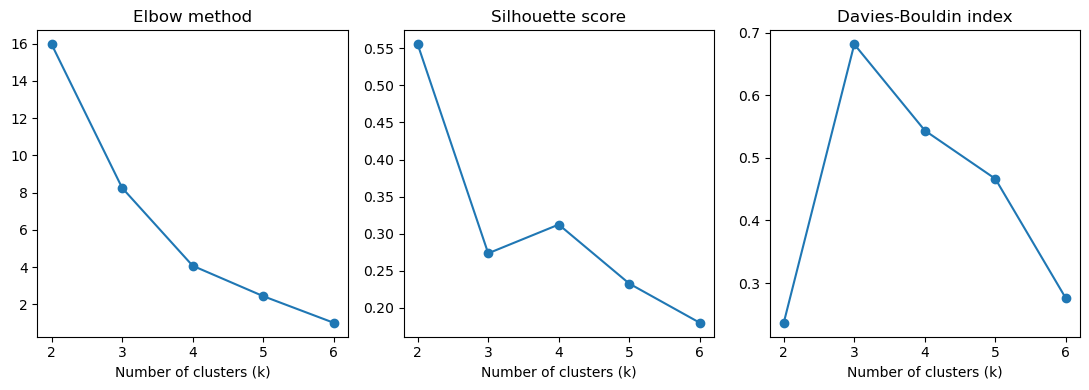

In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Try k = 2..6 
k_range = range(2, 7)
inertia, sil, dbi = [], [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)                          #elbow_method                
    sil.append(silhouette_score(X, labels))              #silhouette_score
    dbi.append(davies_bouldin_score(X, labels))          #davies_bouldin_score

# Summary table of the two metrics
k_results = pd.DataFrame({"k": list(k_range), "Inertia": inertia, "Silhouette": sil, "Davies_Bouldin": dbi}).round(3)
print(k_results)

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].plot(k_range, inertia, marker="o"); axes[0].set_title("Elbow method")
axes[1].plot(k_range, sil, marker="o");     axes[1].set_title("Silhouette score")
axes[2].plot(k_range, dbi, marker="o");      axes[2].set_title("Davies-Bouldin index")
for ax in axes:
    ax.set_xlabel("Number of clusters (k)")
plt.tight_layout()
plt.show()